In [1]:
# Imports, Configre Pandas
import pandas as pd
from sqlalchemy import create_engine, text, inspect

pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

# Reduce Data and Count initial Rows
ENGINE_URL = 'postgresql://markfinlay:@localhost:5432/osm'

# NOTES for Methodology regarding EPSG:3035 -  accurate distance calculations using meters and satellite assets

# EPSG:3035, also known as "ETRS89 / LAEA Europe" (Lambert Azimuthal Equal-Area), is an equal-area projection. 
# This is its most significant advantage for many analytical tasks.

# When performing operations like calculating ST_Length(way) (when creating filtered_planet_osm_line and later in OSM Data.py for segmentation) 
# or if doing any area-based analysis, an equal-area projection ensures that these measurements are accurate across your 
# study area (Ireland and UK). Geographic coordinate systems like WGS84 (EPSG:4326), which use degrees, are not 
# suitable for accurate distance or area measurements directly.

# Why it matters:
# Trail Segmentation: OSM Data.py script segments trails into fixed lengths (e.g., segment_length = 320 meters). 
# Performing this segmentation accurately requires the trail geometries to be in a coordinate system where distances are measured in meters.

# Bounding Box for Satellite Imagery: When fetching Sentinel-2 imagery in Sentinel 2 Data.py, bounding boxs around the centroid of each 
# trail segment. Specify half_side = 160 (meters) to create a 320m x 320m bounding box. 
# These dimensions must be in meters, and the centroid coordinates (center.x, center.y) must also be in a meter-based system for 
# this to work correctly. EPSG:3035 provides this.

# When requesting data from Sentinel Hub using a bounding box defined in a specific CRS (like EPSG:3035 for your seg_bbox), 
# and specify an image size in pixels (e.g., 32x32 pixels for a 320m x 320m area at 10m/pixel resolution), 
# the service handles the spatial gridding correctly based on that CRS. 
# Using a meter-based projected CRS like EPSG:3035 for defining this request ensures that pixel resolution (10 meters per pixel) 
# directly corresponds to the ground sampling distance intended.

In [2]:
try:
    engine = create_engine(ENGINE_URL)
    with engine.connect() as connection:
        print("✅ Successfully connected to the database.")

        # Check for PostGIS extension
        postgis_check = connection.execute(text("SELECT 1 FROM pg_extension WHERE extname = 'postgis';")).scalar_one_or_none()
        if postgis_check:
            print("✅ PostGIS extension is enabled.")
        else:
            print("⚠️ WARNING: PostGIS extension is NOT enabled. This notebook heavily relies on it.")
            print("   Please ensure PostGIS is installed and enabled in the database (setup_db.py should handle this).")

        # Check for HSTORE extension
        hstore_check = connection.execute(text("SELECT 1 FROM pg_extension WHERE extname = 'hstore';")).scalar_one_or_none()
        if hstore_check:
            print("✅ HSTORE extension is enabled.")
        else:
            print("⚠️ WARNING: HSTORE extension is NOT enabled.")
            print("   This might be an issue if osm2pgsql was expected to use it (setup_db.py calls osm2pgsql with --hstore).")

except Exception as e:
    print(f"❌ ERROR: Failed to connect to the database or execute initial checks.")
    print(f"   Details: {e}")
    print("   Please ensure PostgreSQL is running, the database '{DB_NAME}' exists, and connection parameters are correct.")
    print("   You might need to run the `setup_db.py` script first.")
    # Optionally, raise the exception if you want the notebook to stop here on failure
    # raise
else:
    print("\nInitial database checks complete. Proceeding with notebook execution...")
    # Configure Pandas options (from your original first cell)
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', None)

✅ Successfully connected to the database.
✅ PostGIS extension is enabled.
✅ HSTORE extension is enabled.

Initial database checks complete. Proceeding with notebook execution...


In [3]:
print("\n--- Checking for Essential OSM Tables and Data --- \n")

essential_tables = {
    "planet_osm_point": "Points imported by osm2pgsql.",
    "planet_osm_line": "Lines (roads, paths, etc.) imported by osm2pgsql. CRITICAL for this notebook.",
    "planet_osm_polygon": "Polygons imported by osm2pgsql.",
    "planet_osm_roads": "Roads (subset) imported by osm2pgsql."
}

all_essential_tables_present = True
planet_osm_line_has_data = False

if 'engine' in locals() and engine is not None: # Check if engine exists
    try:
        inspector = inspect(engine)
        with engine.connect() as connection:
            for table_name, description in essential_tables.items():
                if inspector.has_table(table_name, schema='public'):
                    count_result = connection.execute(text(f"SELECT COUNT(*) FROM {table_name};")).scalar_one()
                    print(f"✅ Table '{table_name}' exists and has {count_result:,} rows. ({description})")
                    if table_name == "planet_osm_line" and count_result > 0:
                        planet_osm_line_has_data = True
                else:
                    print(f"❌ ERROR: Essential table '{table_name}' does NOT exist. ({description})")
                    all_essential_tables_present = False

            if not all_essential_tables_present:
                print("\nOne or more essential OSM tables are missing. The `setup_db.py` script might not have completed successfully.")
            elif not planet_osm_line_has_data:
                print("\n⚠️ WARNING: Table 'planet_osm_line' exists but is empty. Check the osm2pgsql import in `setup_db.py`.")
            else:
                # Optional: More specific check for relevant data in planet_osm_line
                relevant_lines_query = """
                    SELECT COUNT(*) FROM planet_osm_line
                    WHERE (highway IN ('path', 'footway', 'track') OR route = 'hiking')
                    AND surface IS NOT NULL;
                """
                relevant_lines_count = connection.execute(text(relevant_lines_query)).scalar_one()
                if relevant_lines_count > 0:
                    print(f"✅ Found {relevant_lines_count:,} potentially relevant lines in 'planet_osm_line' (with highway/route and surface tags).")
                else:
                    print("⚠️ WARNING: 'planet_osm_line' has data, but no lines match the initial filtering criteria (highway/route and surface tags).")
                    print("   This could mean the imported PBF files lack these specific tags, or there's an issue with the OSM data itself.")

    except Exception as e:
        print(f"❌ ERROR during table checks: {e}")
        print("   Ensure the database connection is stable and the user has permissions.")
else:
    print("❌ ERROR: Database engine ('engine') not initialized from the previous cell. Cannot perform table checks.")

if not all_essential_tables_present or not planet_osm_line_has_data:
    print("\n🛑 CRITICAL CHECKS FAILED. Review messages above before proceeding with the rest of the notebook.")
else:
    print("\nEssential table checks passed. You should be good to proceed.")
print("-" * 50)


--- Checking for Essential OSM Tables and Data --- 

✅ Table 'planet_osm_point' exists and has 9,705,125 rows. (Points imported by osm2pgsql.)
✅ Table 'planet_osm_line' exists and has 13,850,470 rows. (Lines (roads, paths, etc.) imported by osm2pgsql. CRITICAL for this notebook.)
✅ Table 'planet_osm_polygon' exists and has 24,080,029 rows. (Polygons imported by osm2pgsql.)
✅ Table 'planet_osm_roads' exists and has 751,696 rows. (Roads (subset) imported by osm2pgsql.)
✅ Found 837,727 potentially relevant lines in 'planet_osm_line' (with highway/route and surface tags).

Essential table checks passed. You should be good to proceed.
--------------------------------------------------


In [4]:
# Define the new table name
new_filtered_table_name = "filtered_planet_osm_line"

# SQL query to create the new table with the filtered data
create_new_table_query = f"""
DROP TABLE IF EXISTS {new_filtered_table_name}; -- Optional: Drop if it exists, for idempotency

CREATE TABLE {new_filtered_table_name} AS
SELECT
    osm_id,
    name,
    surface,
    highway,
    route,
    width,
    tags,
    way,
    ST_Length(way) AS length_m
FROM
    planet_osm_line
WHERE
    (highway IN ('path', 'footway', 'track') OR route = 'hiking')
    AND way IS NOT NULL
    AND NOT ST_IsEmpty(way)
    AND ST_Length(way) > 160
    AND surface IS NOT NULL;
"""

# Optional: Add an index on the geometry column for faster spatial queries later
create_index_query = f"""
CREATE INDEX IF NOT EXISTS idx_{new_filtered_table_name}_way
ON {new_filtered_table_name} USING GIST (way);

-- Optional: Index on osm_id if you frequently query by it
CREATE INDEX IF NOT EXISTS idx_{new_filtered_table_name}_osm_id
ON {new_filtered_table_name} (osm_id);
"""

# engine = create_engine('postgresql://markfinlay:@localhost:5432/osm') # Already defined

with engine.begin() as conn:
    print(f"Creating new table '{new_filtered_table_name}' with filtered data...")
    conn.execute(text(create_new_table_query))
    print(f"Table '{new_filtered_table_name}' created successfully.")
    print(f"Creating indexes on '{new_filtered_table_name}'...")
    conn.execute(text(create_index_query))
    print("Indexes created.")

print("Filtered data has been copied to the new table.")

# Now, your query to get the DataFrame should use the new table
query_from_new_table = f"""
    SELECT name, surface, width, tags, way, length_m -- length_m is already calculated
    FROM {new_filtered_table_name}
    ORDER BY osm_id;
"""

df = pd.read_sql(query_from_new_table, engine)
print(f"Number of rows in the new filtered table '{new_filtered_table_name}': {len(df)}")
df.count()

Creating new table 'filtered_planet_osm_line' with filtered data...
Table 'filtered_planet_osm_line' created successfully.
Creating indexes on 'filtered_planet_osm_line'...
Indexes created.
Filtered data has been copied to the new table.
Number of rows in the new filtered table 'filtered_planet_osm_line': 295399


name         23883
surface     295399
width        22965
tags        295399
way         295399
length_m    295399
dtype: int64

In [5]:
df.head()

,name,surface,width,tags,way,length_m
0,Corbenic Poetry Path,gravel,None,"{'lwn': 'yes', 'url': 'https://www.corbenicpoe...",0102000020110F00000E020000AB5966946BF218C15B33...,6485.738370
1,Mavis Grind,core_path,None,"{'lwn': 'yes', 'network': 'lwn', 'osm_uid': '0...",0102000020110F0000460000002641191BB1CE02C1C3A9...,2428.239959
2,Clumber Park Walk,aspalt,None,"{'lwn': 'yes', 'network': 'lwn', 'osm_uid': '0...",0102000020110F000051000000FCF7C9EF8EEDFCC0CA81...,2832.708139
3,Clumber Park Walk,aspalt,None,"{'lwn': 'yes', 'network': 'lwn', 'osm_uid': '0...",0102000020110F0000220000008E9EDF54B5DEFCC0247B...,1681.694441
4,None,paving_stones,None,"{'osm_uid': '0', 'osm_user': '', 'osm_version'...",0102000020110F00000B0000002E1141C54FAB08C1451F...,273.438938


In [6]:
df['length_m'].describe()

count    295399.000000
mean        659.728068
std         804.295960
min         160.000732
25%         249.209919
50%         409.840180
75%         761.814045
max       33062.965355
Name: length_m, dtype: float64

In [7]:
df['surface'].value_counts()

surface
asphalt                                             60823
grass                                               45289
dirt                                                44204
ground                                              31607
gravel                                              29689
                                                    ...  
yes                                                     1
horses_and_bicycles_are_allowed_to_use_this_way.        1
View from E;Bing                                        1
grp                                                     1
acrylic                                                 1
Name: count, Length: 285, dtype: int64

In [8]:
import geopandas as gpd
# Have a close look at Wikclow Hills Data 
# ST_MakeEnvelope(<min_lon>, <min_lat>, <max_lon>, <max_lat>, 4326)

# The use of ST_Transform is important as way column in filtered_planet_osm_line is not in EPSG:3857. 
# Given that osm2pgsql usually imports data in Web Mercator (EPSG:3857) this should work correctly. 

query = """
    SELECT osm_id, name, highway, surface, way, ST_Length(way) AS length_m
    FROM filtered_planet_osm_line
    WHERE ST_Intersects( way, ST_Transform(ST_MakeEnvelope(-6.50, 52.9, -6.2, 53.24, 4326), 3857));
    """

gdf = gpd.read_postgis(query, engine, geom_col='way')
# Convert to WGS84 so that the GeoJSON is in longitude/latitude
gdf = gdf.to_crs(epsg=4326)
gdf.explore(zoom_start=11, location=(53.1, -6.3))

In [9]:
# 2. Create the 'surface_group' column and populate it
# This is Data cleaning and feature engineering to a degree

from sqlalchemy import create_engine, text

with engine.begin() as conn:
    # a) Add the column if it doesn’t already exist
    print("Adding 'surface_group' column to 'filtered_planet_osm_line' ...")
    conn.execute(text("ALTER TABLE filtered_planet_osm_line ADD COLUMN IF NOT EXISTS surface_group text;"))

    # b) Update the column using a CASE expression
    conn.execute(text("""
        UPDATE filtered_planet_osm_line
        SET surface_group = CASE
            WHEN lower(surface) IN (
                'asphalt', 'asphaltsidewalk', 'asphalt;paved', 
                'tarmac', 'bituminous', 'macadam'
            )
            THEN 'asphalt'
            WHEN lower(surface) IN (
                 'concrete', 'concrete asphalt', 'concrete:plates',
                 'concrete:lanes', 'concrete_slabs', 'concrete_with_bitumen', 'cement',
                'unpaved/paved', 'paved', 'paving_stones', 'paving_stones:30',
                'brick', 'bricks', 'paving_stones', 'chipseal',
                'cobblestone', 'cobblestone:flattened'
            )
            THEN 'paved'

            WHEN lower(surface) IN (
                 'gravel', 'fine_gravel', 'gravel,_dirt', 'gravel_and_rock', 'aggregate',
                 'sand/gravel/stones', 'ground;gravel', 'compacted',  'sand;pebbles'
               )
            THEN 'gravel'

            WHEN lower(surface) IN (
                 'dirt', 'dust', 'earth', 'earth,_grass', 'dirt/sand',
                 'dirt; gravel; dirt', 'unpaved', 
                 'ground', 'clay', 'soil'
               )
            THEN 'mud/dirt'

            WHEN lower(surface) IN (
                 'grass', 'grass/trees', 'grass_paver', 'green'
               )
            THEN 'grass'

            ELSE NULL
        END
        WHERE surface IS NOT NULL;
    """))

print("Done!")

Adding 'surface_group' column to 'filtered_planet_osm_line' ...
Done!


In [10]:
# Count instances per surface_group
df_surface_groups = pd.read_sql("""
    SELECT surface_group, COUNT(*) AS count
    FROM filtered_planet_osm_line
    WHERE surface IS NOT NULL
    GROUP BY surface_group
    ORDER BY count DESC
""", engine)
df_surface_groups

,surface_group,count
0,mud/dirt,102613
1,asphalt,60847
2,gravel,45921
3,grass,45367
4,paved,34939
5,None,5712


osm_id           289687
highway          289686
surface          289687
surface_group    289687
tags             289687
way              289687
length_m         289687
dtype: int64


<Axes: xlabel='surface_group'>

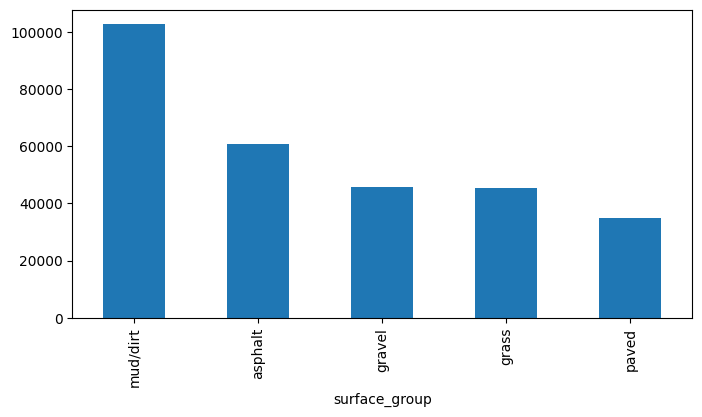

In [11]:
# Simple bar chart of these frequencies
query = """
    SELECT osm_id, highway, surface, surface_group, tags, way, ST_Length(way) AS length_m
    FROM filtered_planet_osm_line
    WHERE surface IS NOT NULL
    AND surface_group IS NOT NULL
    """

gdf = gpd.read_postgis(query, engine, geom_col='way')
print(gdf.count())

gdf['surface_group'].value_counts().plot.bar(figsize=(8, 4))

In [12]:
# Balance the data so that we have an even count matching the smallest class
import pandas as pd

# Define your target count per class
target_count = 30000 # IMPORTANT: Set to the count of the smallest class 'paved' before balancing

# Create a list to collect each balanced group
balanced_frames = []

# Iterate over each surface_group to downsample those about target_count
for group, group_data in gdf.groupby('surface_group'):
    if len(group_data) >= target_count:
        # Downsample majority groups
        balanced_group = group_data.sample(n=target_count, random_state=42)
    balanced_frames.append(balanced_group)

# Combine all groups back into a single GeoDataFrame
gdf_balanced = pd.concat(balanced_frames, ignore_index=True)

# Verify the result
print(gdf_balanced['surface_group'].value_counts())

surface_group
asphalt     30000
grass       30000
gravel      30000
mud/dirt    30000
paved       30000
Name: count, dtype: int64


In [13]:
# Write the balanced GeoDataFrame to a new table in the database.
gdf_balanced = gdf_balanced.to_crs(epsg=3035)

gdf_balanced.to_postgis('balanced_planet_osm_line', engine, if_exists='replace', index=False)
print("New table 'balanced_planet_osm_line' has been created and the balanced data is stored.")

New table 'balanced_planet_osm_line' has been created and the balanced data is stored.


In [14]:
# Select all rows from the balanced table
query = "SELECT * FROM balanced_planet_osm_line;"

# Load the data into a GeoDataFrame.
# Adjust the 'geom_col' parameter if your geometry column is named differently.
balanced_gdf = gpd.read_postgis(query, engine, geom_col='way')

# Display the first few rows
balanced_gdf.head()

,osm_id,highway,surface,surface_group,tags,way,length_m
0,764392131,footway,asphalt,asphalt,"{'footway': 'sidewalk', 'osm_uid': '0', 'osm_u...","LINESTRING (3648926.487 3280312.295, 3648962.4...",229.809839
1,240985498,footway,asphalt,asphalt,"{'lit': 'no', 'osm_uid': '0', 'vehicle': 'no',...","LINESTRING (3706954.893 3268744.815, 3706944.6...",179.337144
2,1159609056,footway,asphalt,asphalt,"{'osm_uid': '0', 'osm_user': '', 'osm_version'...","LINESTRING (3682434.625 3154529.701, 3682418.5...",348.077091
3,906225462,footway,asphalt,asphalt,"{'lit': 'yes', 'footway': 'sidewalk', 'osm_uid...","LINESTRING (3618682.899 3195448.52, 3618688.00...",170.433270
4,1039388177,footway,asphalt,asphalt,"{'footway': 'sidewalk', 'osm_uid': '0', 'osm_u...","LINESTRING (3490750.396 3440368.799, 3490750.2...",776.735068


In [15]:
# Count of each class in the 'surface_group' column
print("\nDistribution of 'surface_group':")
balanced_gdf['surface_group'].value_counts()


Distribution of 'surface_group':


surface_group
asphalt     30000
grass       30000
gravel      30000
mud/dirt    30000
paved       30000
Name: count, dtype: int64

In [16]:
# group-wise statistics for a specific column, you can use groupby.
# For example, the mean length_m per surface_group:
print("\nMean 'length_m' per surface_group:")
balanced_gdf.groupby('surface_group')['length_m'].mean()


Mean 'length_m' per surface_group:


surface_group
asphalt     430.704999
grass       694.447573
gravel      874.358355
mud/dirt    753.376930
paved       434.425647
Name: length_m, dtype: float64


Total 'length_m' per surface_group in balanced_gdf:
surface_group
asphalt     1.292115e+07
grass       2.083343e+07
gravel      2.623075e+07
mud/dirt    2.260131e+07
paved       1.303277e+07
Name: length_m, dtype: float64


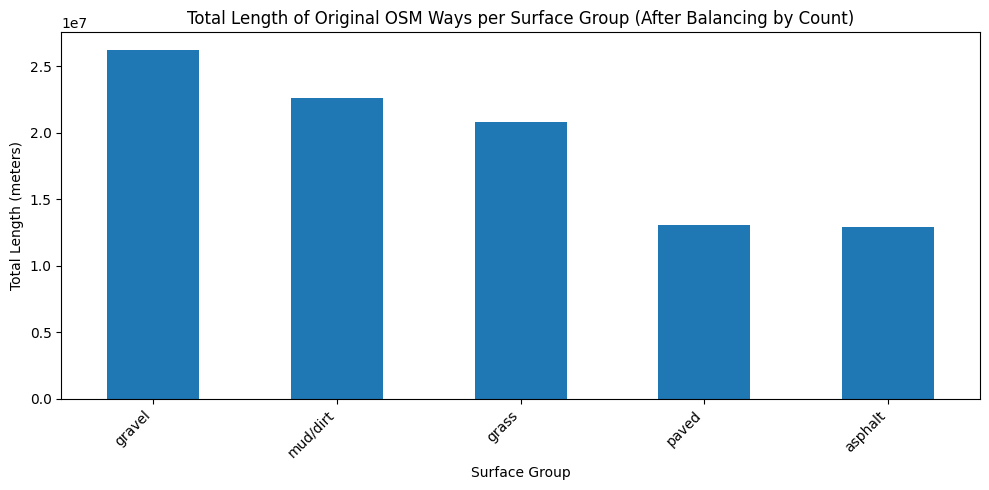

In [17]:
# Calculate total 'length_m' per surface_group
print("\nTotal 'length_m' per surface_group in balanced_gdf:")
total_length_per_group = balanced_gdf.groupby('surface_group')['length_m'].sum()
print(total_length_per_group)

# Optional: Display as a bar chart for easier visual comparison
import matplotlib.pyplot as plt
total_length_per_group.sort_values(ascending=False).plot.bar(figsize=(10, 5))
plt.title('Total Length of Original OSM Ways per Surface Group (After Balancing by Count)')
plt.ylabel('Total Length (meters)')
plt.xlabel('Surface Group')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [18]:
# ── imports ─────────────────────────────────────────────────────────
from math import sqrt
import geopandas as gpd
from shapely.geometry import Point, box
from shapely.ops import substring
from sqlalchemy import text
from rtree import index                       # pip install rtree

# ── parameters ─────────────────────────────────────────────────────
TILE_SIDE = 160.0           # m  — edge of the square
HALF      = TILE_SIDE / 2.0 # 80 m
STRIDE    = TILE_SIDE * sqrt(2)   # 226.274 m  (optimistic jump)
STEP_MIN  = 10.0            # m  — nudge if candidate overlaps

# ── load balanced ways (already EPSG:3035) ─────────────────────────
balanced_sql = """
SELECT osm_id, surface_group, way
FROM   balanced_planet_osm_line;
"""
balanced_gdf = (
    gpd.read_postgis(balanced_sql, engine, geom_col="way")
        .to_crs(3035)
)
print(f"Read {len(balanced_gdf)} OSM ways")

# ── (re)create target table ────────────────────────────────────────
ddl_sql = """
DROP TABLE IF EXISTS trail_segments;
CREATE TABLE trail_segments (
    id            SERIAL PRIMARY KEY,
    filename      TEXT,
    osm_id        BIGINT,
    surface_group TEXT,
    center_geom   geometry(Point, 3035),
    image_data    BYTEA
);
"""
with engine.begin() as conn:
    conn.execute(text(ddl_sql))

insert_sql = text("""
INSERT INTO trail_segments
      (filename,  osm_id,  surface_group,  center_geom, image_data)
VALUES (:filename, :osm_id, :surface_group,
        ST_SetSRID(ST_MakePoint(:x, :y), 3035),
        NULL)
""")

# ── tiling loop ────────────────────────────────────────────────────
rt_idx = index.Index()       # spatial index of accepted squares
tile_id_global = 0           # for filename enumeration

with engine.begin() as conn:
    for _, row in balanced_gdf.iterrows():
        line   = row["way"]
        length = line.length
        pos    = 0.0

        while pos < length:
            # candidate centre & square
            centre = line.interpolate(pos)
            sq     = box(
                centre.x - HALF, centre.y - HALF,
                centre.x + HALF, centre.y + HALF
            )

            # if overlaps any previous square → nudge forward STEP_MIN
            if list(rt_idx.intersection(sq.bounds)):
                pos += STEP_MIN
                continue

            # accept tile
            rt_idx.insert(tile_id_global, sq.bounds)
            tile_id_global += 1

            params = {
                "filename":      f"{row.osm_id}_seg_{tile_id_global}",
                "osm_id":        int(row.osm_id),
                "surface_group": row.surface_group,
                "x":             centre.x,
                "y":             centre.y,
            }
            conn.execute(insert_sql, params)

            # optimistic jump ahead by STRIDE
            pos += STRIDE

print(f"Inserted {tile_id_global} non-overlapping 160 m tiles into trail_segments.")


Read 150000 OSM ways
Inserted 242929 non-overlapping 160 m tiles into trail_segments.


In [19]:
# NEW CELL: Balance the 'trail_segments' by number of segments per surface_group

import pandas as pd
import geopandas as gpd
from sqlalchemy import text # engine should already be defined

print("--- Balancing trail_segments ---")

# 1. Read all segments from the 'trail_segments' table
print("Reading all segments from 'trail_segments' table...")
query_all_segments = "SELECT id, filename, osm_id, surface_group, center_geom FROM trail_segments;"
all_segments_gdf = gpd.read_postgis(query_all_segments, engine, geom_col='center_geom')
print(f"Read {len(all_segments_gdf)} total segments.")

if all_segments_gdf.empty:
    print("No segments found in 'trail_segments' table. Skipping balancing.")
else:
    # 2. Calculate current counts of 320m segments per surface_group
    print("\nCurrent segment counts per surface_group in 'trail_segments':")
    segment_counts_per_group = all_segments_gdf['surface_group'].value_counts()
    print(segment_counts_per_group)

    if segment_counts_per_group.empty:
        print("No surface_group data to balance. Skipping.")
    else:
        # 3. Determine the target count for balancing (e.g., count of the smallest class)
        target_segment_count = segment_counts_per_group.min()
        print(f"\nTarget segment count for balancing (smallest class size): {target_segment_count}")

        balanced_segment_frames = []
        for group, group_data in all_segments_gdf.groupby('surface_group'):
            if len(group_data) >= target_segment_count:
                # Downsample majority groups
                balanced_group = group_data.sample(n=target_segment_count, random_state=42)
            else:
                # Oversample minority groups (with replacement)
                # This path will only be taken if you set target_segment_count to something other than .min()
                # or if you want to ensure even the smallest class reaches a certain threshold.
                # For now, with .min(), only downsampling will occur.
                balanced_group = group_data.sample(n=target_segment_count, replace=True, random_state=42)
            balanced_segment_frames.append(balanced_group)

        if balanced_segment_frames:
            final_balanced_segments_gdf = pd.concat(balanced_segment_frames, ignore_index=True)
            print("\nCounts per surface_group after final balancing of segments:")
            print(final_balanced_segments_gdf['surface_group'].value_counts())

            # 4. Write the finally balanced segments to a new table
            final_balanced_table_name = "final_balanced_trail_segments"
            print(f"\nWriting {len(final_balanced_segments_gdf)} balanced segments to new table '{final_balanced_table_name}'...")

            # Ensure it's in the correct CRS before writing (should inherit from trail_segments' center_geom)
            # but good to be explicit if trail_segments was created with a specific CRS like 3035 for center_geom.
            # final_balanced_segments_gdf = final_balanced_segments_gdf.to_crs(epsg=3035) # If needed

            with engine.connect() as conn: # Drop if exists for idempotency
                conn.execute(text(f"DROP TABLE IF EXISTS {final_balanced_table_name};"))
                conn.commit() # Commit drop before creating
            
            final_balanced_segments_gdf.to_postgis(
                final_balanced_table_name,
                engine,
                if_exists='append', # Use 'append' because we just dropped it, or 'replace' if you don't manually drop
                index=False,
                # Explicitly define geometry type and srid if needed, though usually inferred
                # dtype={'center_geom': 'geometry(Point,3035)'}
            )
            print(f"Table '{final_balanced_table_name}' created with balanced segments.")

            # Optional: Add an index
            with engine.begin() as conn:
                 conn.execute(text(f"CREATE INDEX IF NOT EXISTS idx_{final_balanced_table_name}_geom ON {final_balanced_table_name} USING GIST (center_geom);"))
                 conn.execute(text(f"CREATE INDEX IF NOT EXISTS idx_{final_balanced_table_name}_sg ON {final_balanced_table_name} (surface_group);"))
            print(f"Indexes created on '{final_balanced_table_name}'.")

        else:
            print("No balanced segment frames created. Final table not written.")

--- Balancing trail_segments ---
Reading all segments from 'trail_segments' table...
Read 242929 total segments.

Current segment counts per surface_group in 'trail_segments':
surface_group
gravel      66966
mud/dirt    59897
grass       55969
asphalt     35573
paved       24524
Name: count, dtype: int64

Target segment count for balancing (smallest class size): 24524

Counts per surface_group after final balancing of segments:
surface_group
asphalt     24524
grass       24524
gravel      24524
mud/dirt    24524
paved       24524
Name: count, dtype: int64

Writing 122620 balanced segments to new table 'final_balanced_trail_segments'...
Table 'final_balanced_trail_segments' created with balanced segments.
Indexes created on 'final_balanced_trail_segments'.


In [20]:
# Segements are Balanced!
# Select all rows from trail_segments
query = "SELECT * FROM final_balanced_trail_segments;"

# Load the data into a GeoDataFrame.
trail_segments_gpdf= gpd.read_postgis(query, engine, geom_col='center_geom')

# Display the first few rows
trail_segments_gpdf.head()

,id,filename,osm_id,surface_group,center_geom
0,22878,34426774_seg_22878,34426774,asphalt,POINT (3464845.236 3230836.741)
1,16802,331713835_seg_16802,331713835,asphalt,POINT (3447717.699 3575770.59)
2,32693,4524415_seg_32693,4524415,asphalt,POINT (3713802.548 3251283.806)
3,8194,8410593_seg_8194,8410593,asphalt,POINT (3613508.085 3194943.253)
4,18838,1306397815_seg_18838,1306397815,asphalt,POINT (3542707.49 3782465.408)


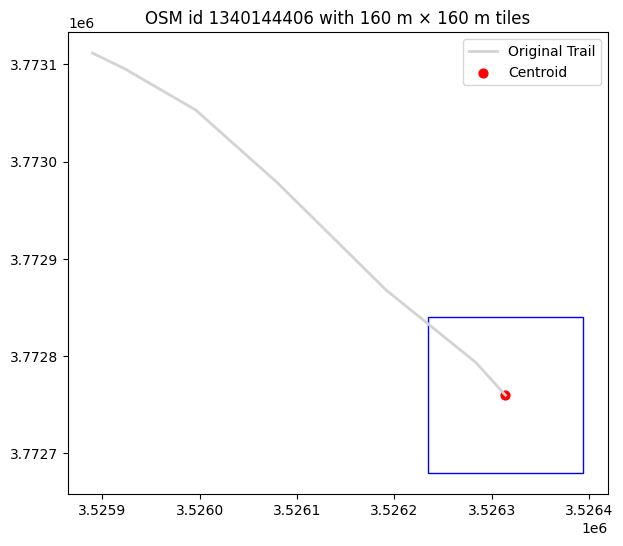

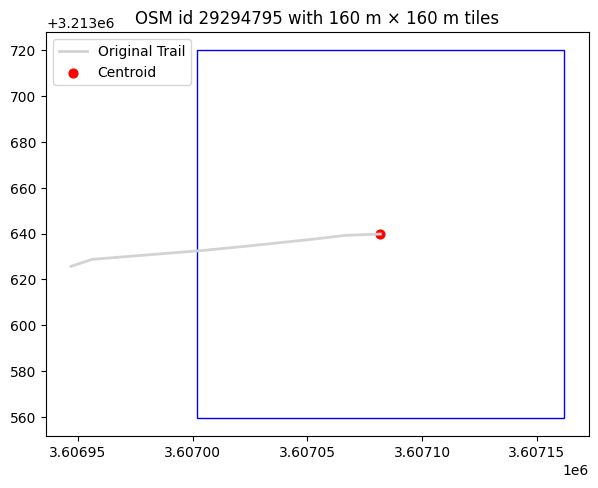

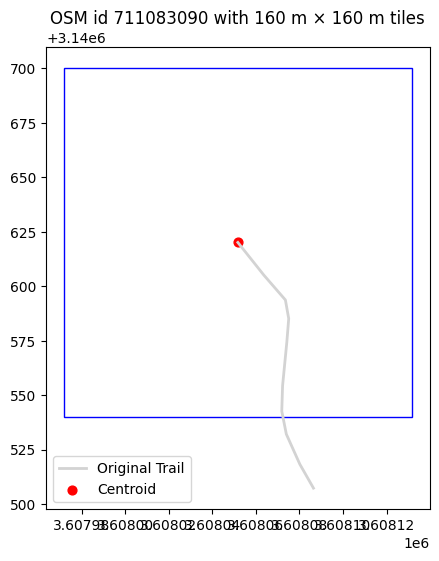

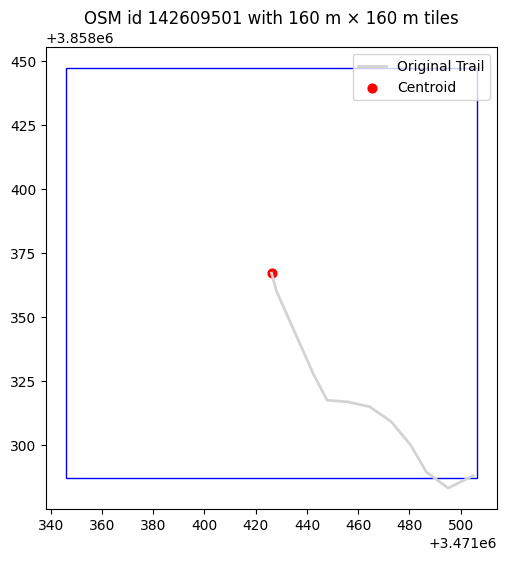

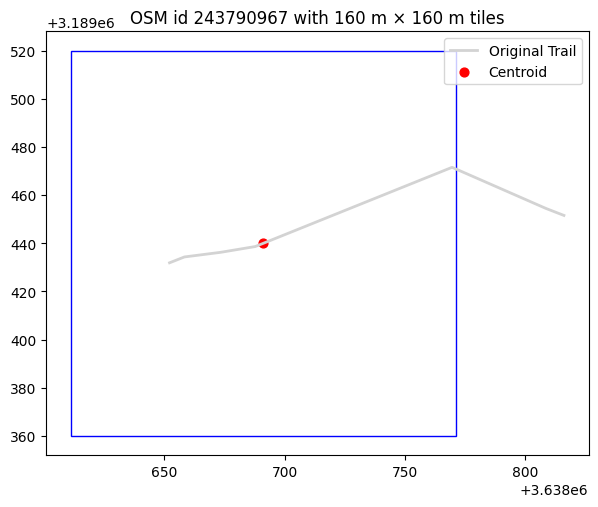

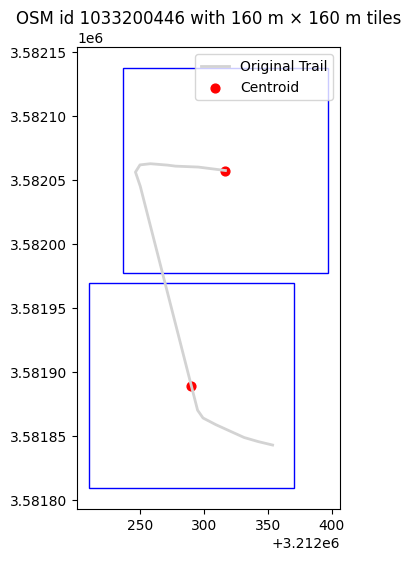

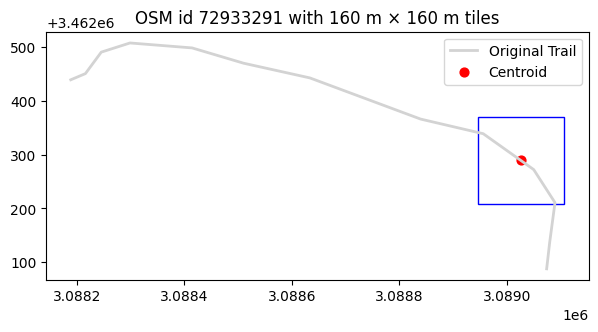

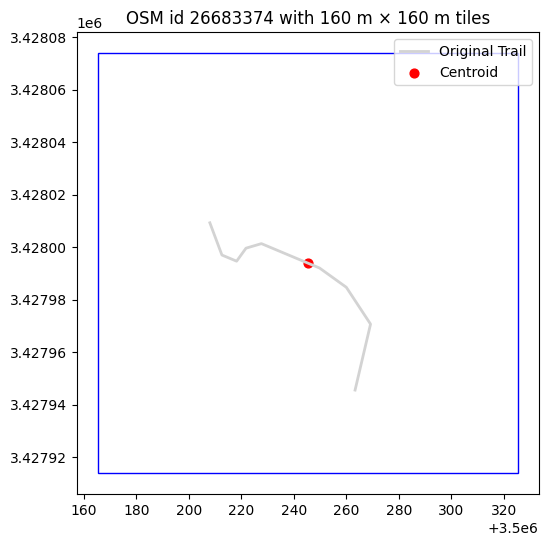

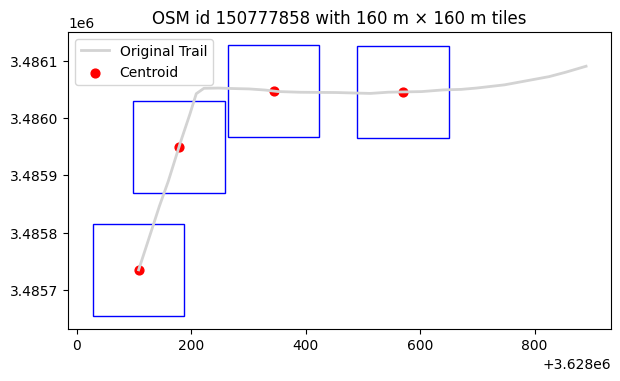

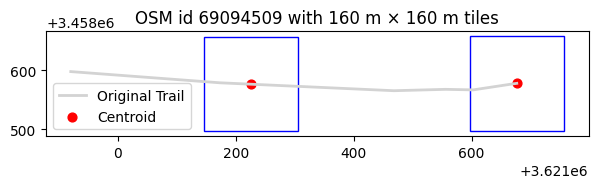

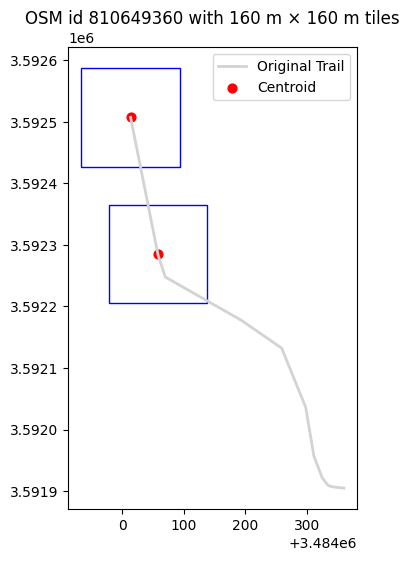

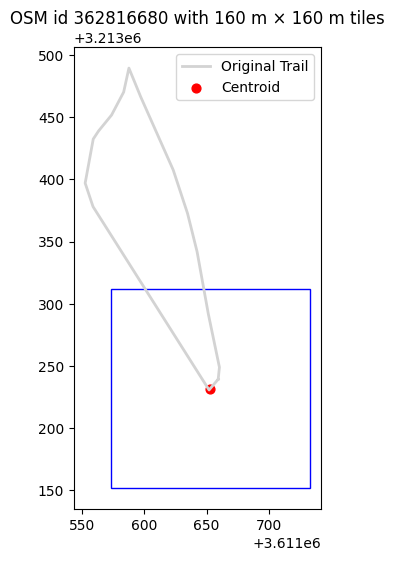

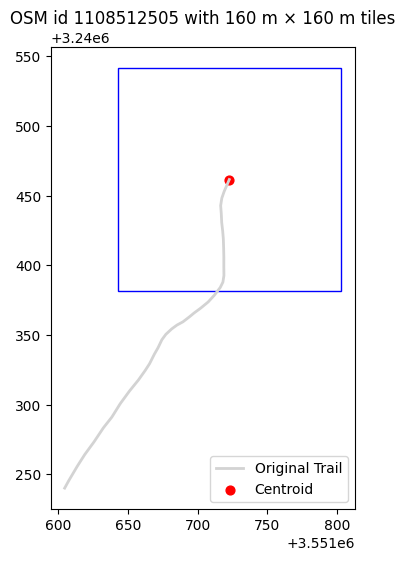

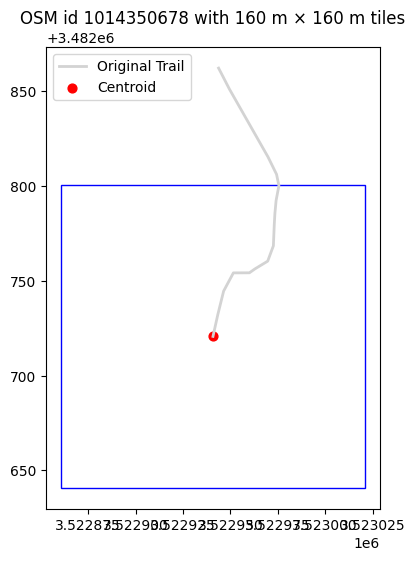

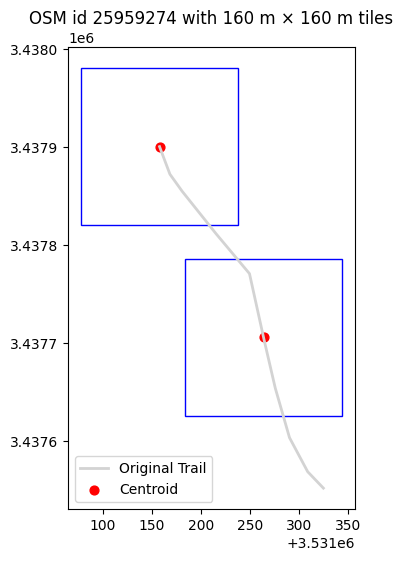

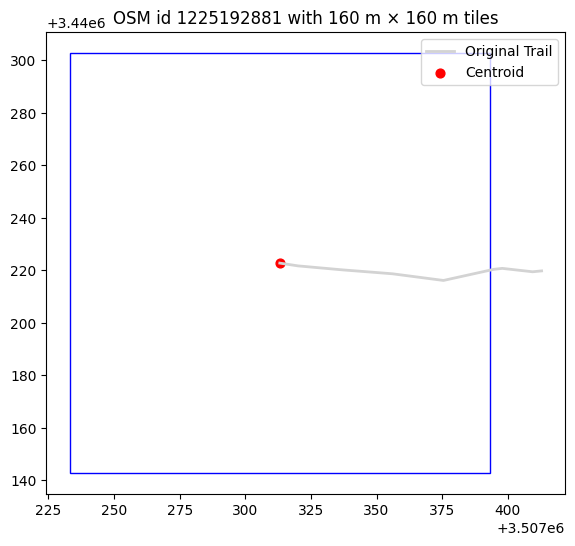

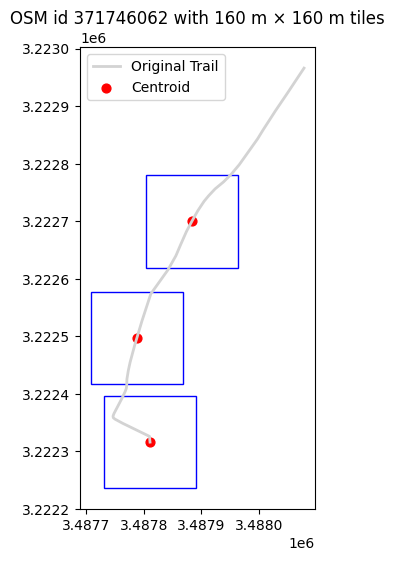

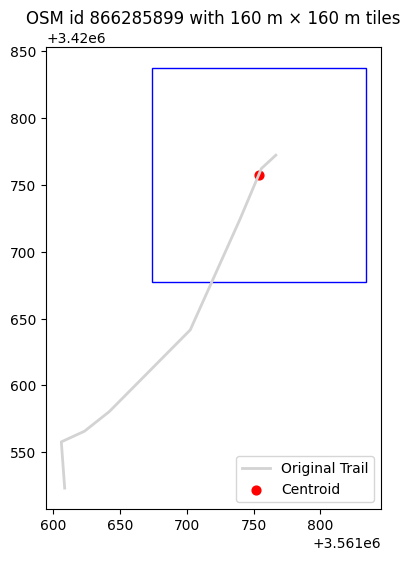

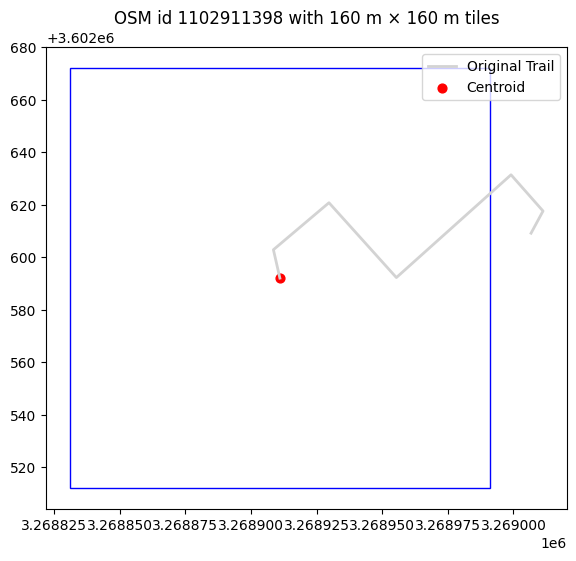

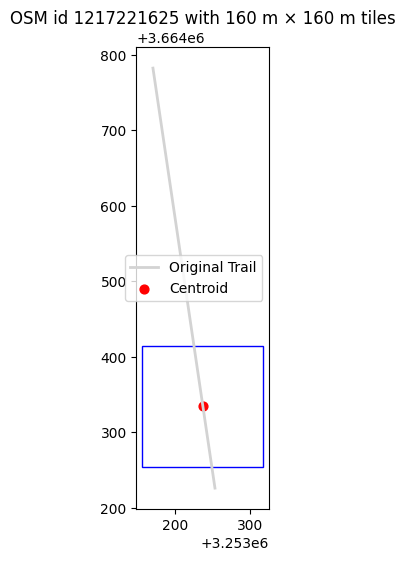

In [25]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

BOX_SIDE = 160.0          # length of one square’s edge (m)
HALF     = BOX_SIDE / 2.0 # half-edge for quick offsets

# 1) pick 20 random OSM IDs from the segment table
osm_ids = (
    pd.read_sql(
        "SELECT DISTINCT osm_id FROM final_balanced_trail_segments",
        engine
    )
    .sample(n=20, random_state=42)["osm_id"]
)

for osm_id in osm_ids:

    # 2) fetch the original LineString for this way
    line_sql = f"""
        SELECT way
        FROM   balanced_planet_osm_line
        WHERE  osm_id = {osm_id}
        LIMIT 1;
    """
    line_gdf   = gpd.read_postgis(line_sql, engine,
                                  geom_col="way", crs="EPSG:3035")
    trail_line = line_gdf.geometry.iloc[0]          # <-- fixed accessor

    # 3) fetch all centroids belonging to this way
    seg_sql = f"""
        SELECT center_geom
        FROM   final_balanced_trail_segments
        WHERE  osm_id = {osm_id};
    """
    segs = gpd.read_postgis(seg_sql, engine,
                            geom_col="center_geom", crs="EPSG:3035")

    # 4) plot
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.plot(*trail_line.xy, color="lightgrey", lw=2, label="Original Trail")
    ax.scatter(segs.center_geom.x, segs.center_geom.y,
               color="red", s=40, label="Centroid")

    for c in segs.center_geom:
        ax.add_patch(
            Rectangle((c.x - HALF, c.y - HALF), BOX_SIDE, BOX_SIDE,
                      facecolor="none", edgecolor="blue", lw=1)
        )

    ax.set_aspect("equal")
    ax.set_title(f"OSM id {osm_id} with {int(BOX_SIDE)} m × {int(BOX_SIDE)} m tiles")
    ax.legend()
    plt.show()
